1 - Try to build a classifier for the MNIST dataset that achieves over 97% accuracy
on the test set. Hint: the KNeighborsClassifier works quite well for this task;
you just need to find good hyperparameter values (try a grid search on the
weights and n_neighbors hyperparameters).


In [ ]:
from sklearn.datasets import fetch_openml

In [ ]:
mnist = fetch_openml('mnist_784', as_frame=False)
X, y = mnist.data, mnist.target

In [ ]:
import matplotlib.pyplot as plt

X_train, X_test, y_train, y_test = X[:60_000], X[60_000:], y[:60000], y[60000:]

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

knn_clf = KNeighborsClassifier(n_neighbors=3, weights='distance')
# param_grid = [
#     {'n_neighbors': [3,8,15],
#     'weights': ['uniform', 'distance'],}
# ]

# knn_grid = GridSearchCV(knn_clf, param_grid=param_grid, cv=3)
# knn_grid.fit(X_train, y_train)


KNeighborsClassifier(n_neighbors=3, weights='distance')


In [ ]:
# knn_clf.fit(X_train, y_train)

In [ ]:

# tunned_accuracy = knn_clf.score(X_test, y_test)

In [ ]:
# tunned_accuracy

You can use the shift() function from the scipy.ndimage.interpolation module

In [ ]:
from scipy.ndimage import shift

def shift_image(image, dy, dx):
  image = image.reshape((28, 28))
  shifted_im = shift(image, [dy, dx], cval=0, mode='constant')
  return shifted_im.reshape([-1])


In [ ]:
X_train_aug = [i for i in X_train]
y_train_aug = [i for i in y_train]

for dy, dx in ((1,0), (-1,0), (0, -1), (0, 1)):
  for image, label in zip(X_train, y_train):
    X_train_aug.append(shift_image(image, dy, dx))
    y_train_aug.append(label)

In [ ]:
import numpy as np
X_train_aug = np.array(X_train_aug)
y_train_aug = np.array(y_train_aug)

shuf_idx = np.random.permutation(len(X_train_aug))
X_train_aug = X_train_aug[shuf_idx]
y_train_aug = y_train_aug[shuf_idx]

In [ ]:
# knn_clf = KNeighborsClassifier(n_neighbors=4, weights='distance')
# knn_clf.fit(X_train_aug, y_train_aug)

In [ ]:
# score = knn_clf.score(X_test, y_test)

In [ ]:
# score

In [ ]:
# erro_rate_change = (1 - tunned_accuracy) / (1 - score) - 1

In [ ]:
# print(f"{erro_rate_change:.0%}")

#Atividade 3, titanic

In [ ]:
from pathlib import Path
import tarfile
import urllib.request
import pandas as pd

def load_titanic_set():
  titanic_path = Path("dados/titanic.tgz")
  if not titanic_path.is_file():
    Path("dados").mkdir(parents=True, exist_ok=True)
    url = "https://homl.info/titanic.tgz"
    urllib.request.urlretrieve(url, titanic_path)
  with tarfile.open(titanic_path) as titan_tar:
    titan_tar.extractall(path='dados', filter='data')
  return [pd.read_csv(Path("dados/titanic") / filename)
          for filename in ("train.csv", "test.csv")]

train_data, test_data = load_titanic_set()



/tmp/ipykernel_1193/2966193534.py:13: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  titan_tar.extractall(path='dados')


In [ ]:
train_data = train_data.set_index('PassengerId')
test_data = test_data.set_index('PassengerId')

In [ ]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    object 
 3   Sex       891 non-null    object 
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    object 
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    object 
 10  Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 83.5+ KB


In [ ]:
train_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
corr_data = train_data.corr(numeric_only=True)
corr_data["Survived"].sort_values(ascending=False)

,Survived
Survived,1.000000
Fare,0.257307
Parch,0.081629
SibSp,-0.035322
Age,-0.077221
Pclass,-0.338481


##FEATURE ENGINEERING

In [ ]:
train_data['AgeBucket'] = pd.cut(train_data['Age'],
                              bins=[0, 12, 17, 34, 60, np.inf],
                              labels=['Child', 'Teen', 'Young_Adult', 'Adult',
                                      'Senior'])
train_data['RelativesOnboard'] = train_data['SibSp'] + train_data['Parch']

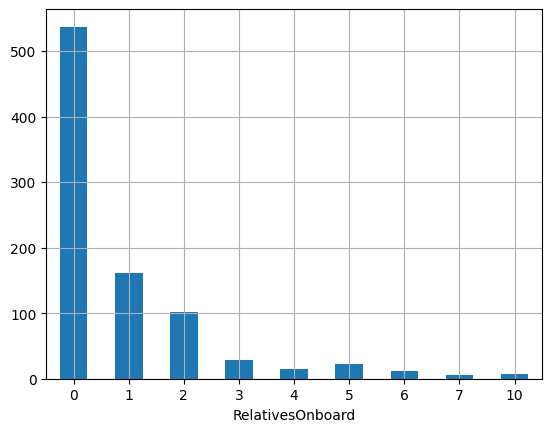

In [ ]:
train_data['RelativesOnboard'].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.show()

In [ ]:
train_data['Titles'] = train_data['Name'].str.extract(r",\s*([^.]*)\.")

In [ ]:
titles_count = train_data['Titles'].value_counts()
rare_title = titles_count[titles_count < 10].index
train_data['Titles'] = train_data['Titles'].replace(rare_title, 'rare')

In [ ]:
train_data['Cabin'].value_counts().sort_index()

,count
Cabin,
A10,1
A14,1
A16,1
A19,1
A20,1
...,...
F33,3
F38,1
F4,2


In [ ]:
train_data['LCabin'] = train_data['Cabin'].str[0]

In [ ]:
train_data['LCabin'].value_counts().sort_index()

,count
LCabin,
A,15
B,47
C,59
D,33
E,32
F,13
G,4
T,1


#PIPELINE

In [ ]:
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# cat_feature = ['Pclass', 'Sex', 'Embarked'] #-> Antes Feature ENGINEERING
# num_feature = ['SibSp', 'Age', 'Parch', 'Fare'] #-> Antes Feature ENGINEERING

cat_feature = ['Pclass', 'Sex', 'Embarked', 'AgeBucket', 'RelativesOnboard',
               'Titles', 'LCabin']
num_feature = ['Fare']


cat_pipeline = Pipeline([
    ('ordinal', OrdinalEncoder()),
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('one_hot',OneHotEncoder(handle_unknown='ignore')),
])

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [ ]:
from sklearn.compose import ColumnTransformer

preprocessing_pipeline = ColumnTransformer([
    ('num', num_pipeline, num_feature),
    ('cat', cat_pipeline, cat_feature),
])

In [ ]:
X_train = preprocessing_pipeline.fit_transform(train_data)

In [ ]:
y_train = train_data['Survived']

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

forest_clf = RandomForestClassifier(n_estimators=300,random_state=42)

param_grid = [
    {'n_estimators': [300, 350, 400]}
]

#forest_grid = GridSearchCV(forest_clf, param_grid=param_grid, cv=10)
#forest_grid.fit(X_train, y_train)


forest_clf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=300, random_state=42)

In [ ]:
#forest_grid.best_score_

In [ ]:
from sklearn.model_selection import cross_val_score
forest_score = cross_val_score(forest_clf, X_train, y_train, cv=10)


In [ ]:
forest_score.mean()

np.float64(0.8126217228464417)

In [ ]:
from sklearn.svm import SVC

svm_clf = SVC(gamma='auto')

svm_score = cross_val_score(svm_clf, X_train, y_train, cv=10)

In [ ]:
svm_score.mean()

np.float64(0.8249313358302123)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier()

param_knn = [
    {'n_neighbors':[5, 10, 15],
     'weights':['uniform', 'distance']}
]

knn_grid = GridSearchCV(knn_clf, param_grid=param_knn, cv=10, refit=False)
knn_grid.fit(X_train, y_train)


GridSearchCV(cv=10, estimator=KNeighborsClassifier(),
             param_grid=[{'n_neighbors': [5, 10, 15],
                          'weights': ['uniform', 'distance']}],
             refit=False)

In [ ]:
knn_grid.best_params_

{'n_neighbors': 10, 'weights': 'uniform'}

In [ ]:
knn_clf = KNeighborsClassifier(**knn_grid.best_params_)

knn_score = cross_val_score(knn_clf, X_train, y_train, cv=10)

In [ ]:
knn_score.mean()

np.float64(0.8092259675405744)

In [ ]:
from xgboost import XGBClassifier

xgb_clf = XGBClassifier()

param_xgb = [
    {'n_estimators': [50, 100,],
     'max_depth': [3, 6]}
]

xgb_grid = GridSearchCV(xgb_clf, param_grid=param_xgb, cv=10, refit=False)
xgb_grid.fit(X_train, y_train)

GridSearchCV(cv=10,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=True, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             param_grid=[{'max_depth': [3, 6], 'n_estimators': [50, 100]}],
             refit=False)

In [ ]:
xgb_final = XGBClassifier(random_state=42 ,**xgb_grid.best_params_)

In [ ]:
xgb_score = cross_val_score(xgb_final, X_train, y_train, cv=10)

In [ ]:
xgb_score.mean()

np.float64(0.8339200998751561)

In [ ]:
xgb_score.std()

np.float64(0.039693466291749586)

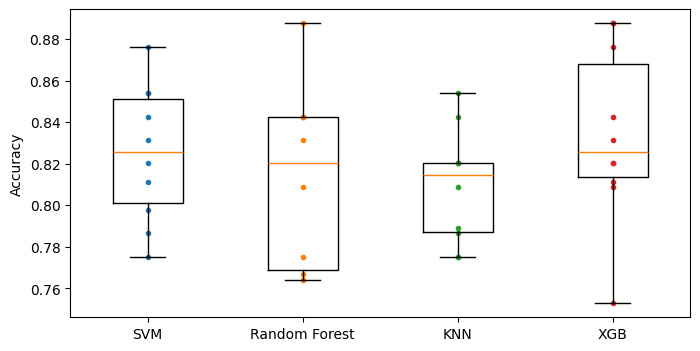

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot([1]*10, svm_score, ".")
plt.plot([2]*10, forest_score, ".")
plt.plot([3]*10, knn_score, ".")
plt.plot([4]*10, xgb_score, '.')
plt.boxplot([svm_score, forest_score, knn_score, xgb_score],
            tick_labels=('SVM', 'Random Forest', 'KNN', 'XGB'))
plt.ylabel("Accuracy")
plt.show()